# Vòng siêu tham số ban đầu

Mở từ thư mục dự án với kernel của môi trường dự án. Các ô đọc config, bảng và hình đã công bố.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import Image, display

here = Path.cwd().resolve()
root = next(p for p in [here, *here.parents] if (p / "reports/stage5_inputs.json").is_file())
sys.path.insert(0, str(root))
from src.wrmsse_stage5 import STAGE2, STAGE3, STAGE4, SELECTED, TABLES, csv, read, check_gates
check_gates()

def table(name):
    return csv(TABLES / (name + ".csv"))

def figure(number):
    path, = (root / "reports/figures").glob(f"{number:02d}_*.png")
    display(Image(filename=str(path), width=950))


RF-01–RF-05 dùng RF-v1 và cùng mẫu Train. Chọn WRMSSE Validation thấp nhất. Kết quả RF-04 cung cấp cấu hình cho ablation. [Mã điều phối và tạo các lượt](../scripts/run_stage3.py).

,experiment,validation_wrmsse,fit_seconds,n_jobs,reuse
3,RF-04,0.675729,196.296110,4,False
4,RF-05,0.676115,268.079367,4,False
2,RF-03,0.745954,57.477103,4,False
1,RF-02,0.747390,36.118079,4,False
0,RF-01,0.798704,14.378836,4,False


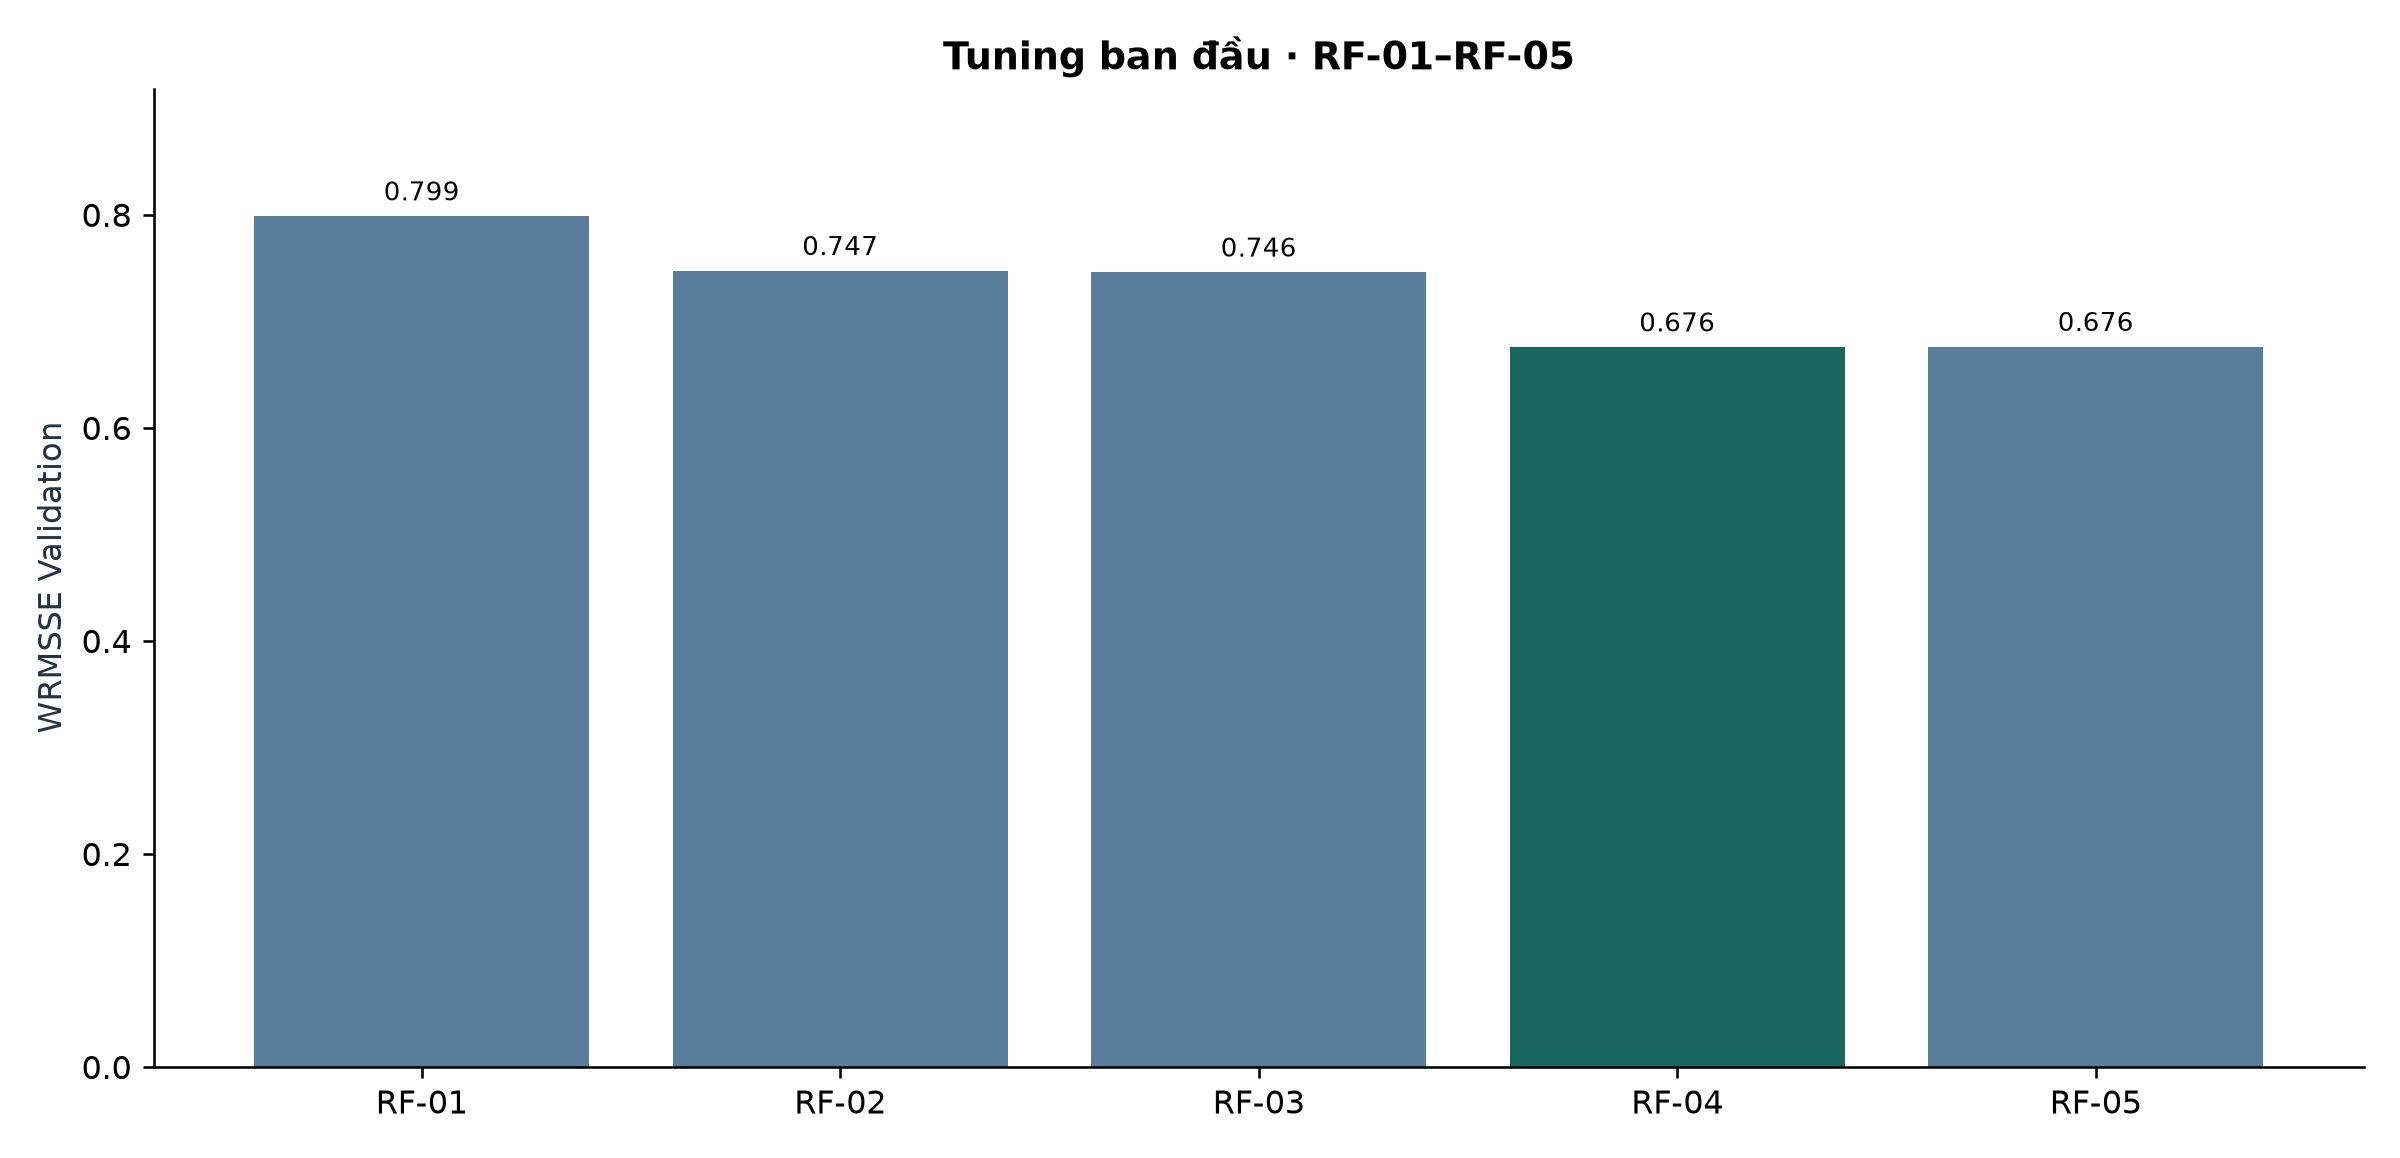

In [2]:
initial = table("experiment_results").query("group == 'initial'").sort_values("validation_wrmsse")
display(initial[["experiment", "validation_wrmsse", "fit_seconds", "n_jobs", "reuse"]])
figure(3)